# Homework 4: Evaluation — worked solutions

This notebook follows the pinned 2026 lead-scoring homework data and the exact train/validation split in the assignment. Run the cells from top to bottom. The answer summary is at the end; each section also prints its result.

**Target:** `converted` (1 means the lead converted).

## Setup and data preparation

Missing categorical values become the string `NA`; missing numeric values become `0.0`. We keep the test split aside and use the prescribed 60% / 20% / 20% train, validation, and test split.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
target = 'converted'

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

# Required split calls from the homework
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(f'train={len(df_train)}, validation={len(df_val)}, test={len(df_test)}')
print('Missing values remaining:', int(df.isnull().sum().sum()))

train=3000, validation=1000, test=1000
Missing values remaining: 0


## Question 1: ROC AUC feature importance

Use each numeric feature itself as a score for predicting conversion. AUC below 0.5 means the feature ranks positives in the reverse direction, so negate that score. The best feature here is `lead_score` (AUC ≈ **0.788**).

In [2]:
y_train = df_train[target]
features_q1 = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

feature_aucs = {}
for feature in features_q1:
    auc = roc_auc_score(y_train, df_train[feature])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])
    feature_aucs[feature] = auc

sorted(feature_aucs.items(), key=lambda item: item[1], reverse=True)

[('lead_score', 0.7882254810906102),
 ('interaction_count', 0.7649203047563227),
 ('number_of_courses_viewed', 0.7229894623989618),
 ('annual_income', 0.6081977776250831)]

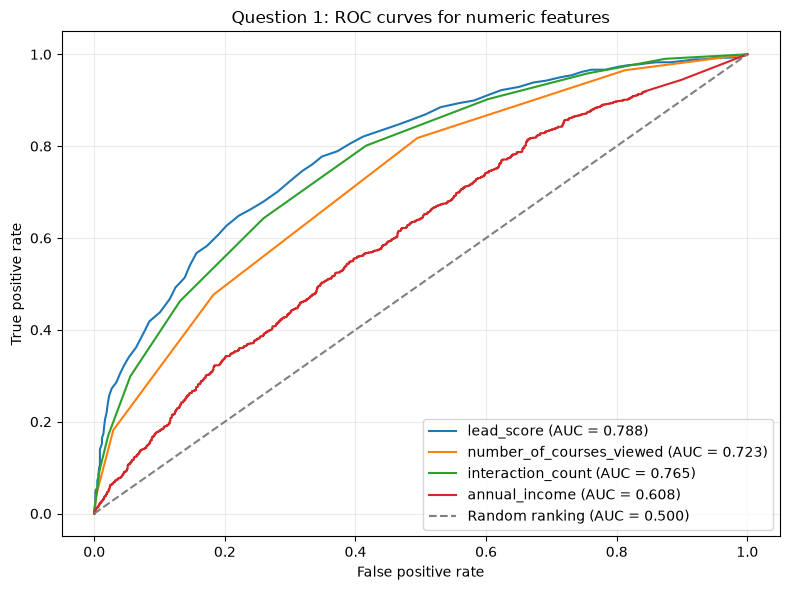

In [3]:
plt.figure(figsize=(8, 6))
for feature in features_q1:
    scores = df_train[feature].to_numpy()
    auc = roc_auc_score(y_train, scores)
    if auc < 0.5:
        scores = -scores
        auc = roc_auc_score(y_train, scores)
    fpr, tpr, _ = roc_curve(y_train, scores)
    plt.plot(fpr, tpr, label=f'{feature} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random ranking (AUC = 0.500)')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Question 1: ROC curves for numeric features')
plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Question 2: Train logistic regression

`DictVectorizer` converts each row's categorical and numeric fields into a numeric feature vector. Logistic regression returns a probability for class 1; ROC AUC evaluates how well these probabilities rank converted leads above non-converted leads across all possible cutoffs.

**Validation AUC: 0.732** (rounded to three decimals).

In [4]:
features = categorical + numerical

def make_dicts(frame):
    return frame[features].to_dict(orient='records')

train_dicts = make_dicts(df_train)
val_dicts = make_dicts(df_val)

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_val_pred = model.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_val_pred)
print(f'Validation AUC: {auc_val:.3f}')

Validation AUC: 0.732


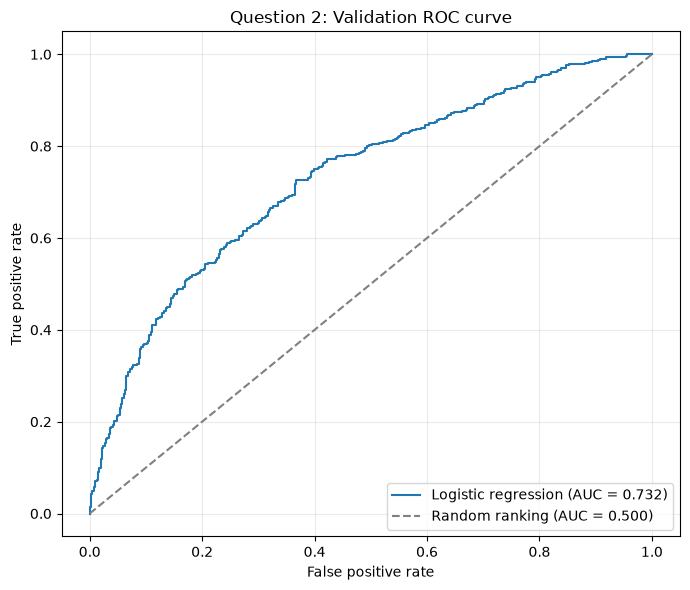

In [5]:
fpr_model, tpr_model, _ = roc_curve(y_val, y_val_pred)
plt.figure(figsize=(7, 6))
plt.plot(fpr_model, tpr_model, label=f'Logistic regression (AUC = {auc_val:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random ranking (AUC = 0.500)')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Question 2: Validation ROC curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Question 3: Precision and recall

For each cutoff, predict converted when the predicted probability is at least that cutoff. Precision answers “of the leads predicted converted, what fraction really converted?” Recall answers “of the actual converted leads, what fraction did we find?”

Compare the two metrics over thresholds 0.00 through 1.00. Ignore cases where both are zero and select the threshold with the smallest absolute difference. It is **0.63**.

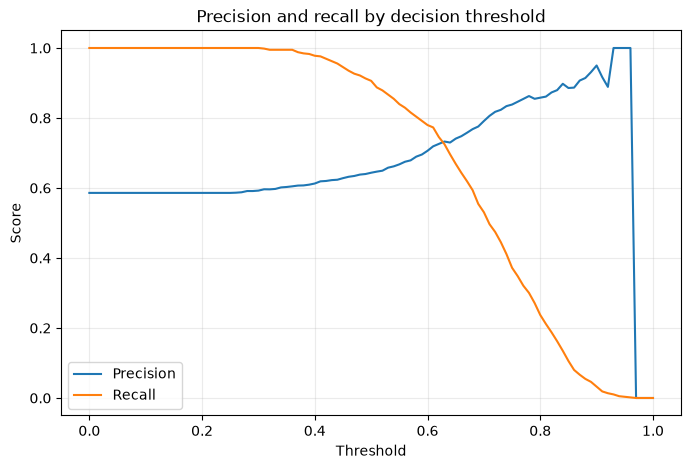

Threshold: 0.63; precision=0.733; recall=0.725


In [6]:
thresholds = np.arange(0.0, 1.001, 0.01)
precisions, recalls = [], []
for threshold in thresholds:
    y_pred = (y_val_pred >= threshold).astype(int)
    precisions.append(precision_score(y_val, y_pred, zero_division=0))
    recalls.append(recall_score(y_val, y_pred, zero_division=0))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and recall by decision threshold')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

valid = [(abs(p - r), t, p, r) for t, p, r in zip(thresholds, precisions, recalls) if p != 0 or r != 0]
_, best_intersection_threshold, p_at_intersection, r_at_intersection = min(valid)
print(f'Threshold: {best_intersection_threshold:.2f}; precision={p_at_intersection:.3f}; recall={r_at_intersection:.3f}')

## Question 4: F1 score

F1 is the harmonic mean of precision and recall, so it is high only when both are reasonably high. We compute it at the same 0.01 threshold intervals. The maximum occurs at **0.41**.

In [7]:
f1_scores = []
for precision, recall in zip(precisions, recalls):
    f1_scores.append(2 * precision * recall / (precision + recall) if precision + recall else 0.0)

best_f1_index = int(np.argmax(f1_scores))
print(f'Max F1: {f1_scores[best_f1_index]:.3f} at threshold {thresholds[best_f1_index]:.2f}')

Max F1: 0.758 at threshold 0.41


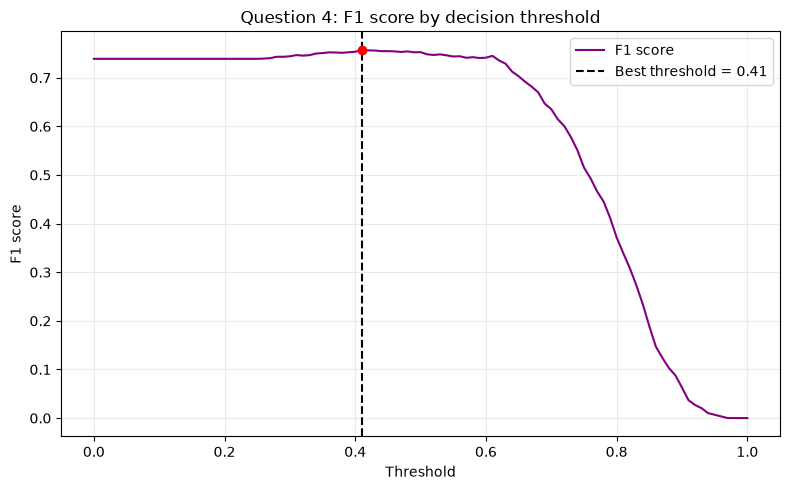

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores, color='purple', label='F1 score')
plt.axvline(thresholds[best_f1_index], color='black', linestyle='--', label=f'Best threshold = {thresholds[best_f1_index]:.2f}')
plt.scatter([thresholds[best_f1_index]], [f1_scores[best_f1_index]], color='red', zorder=3)
plt.xlabel('Threshold')
plt.ylabel('F1 score')
plt.title('Question 4: F1 score by decision threshold')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Question 5: 5-fold cross-validation

Each fold uses four fifths of `df_full_train` to fit a fresh vectorizer and model, then measures ROC AUC on the remaining fifth. The standard deviation uses NumPy's population standard deviation (`np.std`, `ddof=0`), as in the course workflow. The standard deviation is approximately **0.007**.

In [9]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)

def evaluate_cv(C):
    scores = []
    for train_idx, val_idx in kf.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        fold_dv = DictVectorizer(sparse=False)
        X_fold_train = fold_dv.fit_transform(make_dicts(fold_train))
        X_fold_val = fold_dv.transform(make_dicts(fold_val))
        y_fold_train = fold_train[target].to_numpy()
        y_fold_val = fold_val[target].to_numpy()

        fold_model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        fold_model.fit(X_fold_train, y_fold_train)
        fold_pred = fold_model.predict_proba(X_fold_val)[:, 1]
        scores.append(roc_auc_score(y_fold_val, fold_pred))
    return np.array(scores)

scores = evaluate_cv(C=1.0)
print('Fold AUCs:', np.round(scores, 3))
print(f'Mean: {scores.mean():.3f}; standard deviation: {scores.std():.3f}')

Fold AUCs: [0.731 0.73  0.736 0.741 0.721]
Mean: 0.732; standard deviation: 0.007


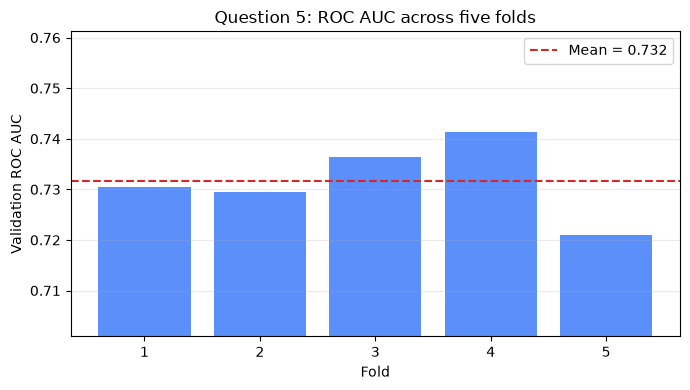

In [10]:
plt.figure(figsize=(7, 4))
fold_numbers = np.arange(1, len(scores) + 1)
plt.bar(fold_numbers, scores, color='#5B8FF9')
plt.axhline(scores.mean(), color='#D62728', linestyle='--', label=f'Mean = {scores.mean():.3f}')
plt.xticks(fold_numbers)
plt.xlabel('Fold')
plt.ylabel('Validation ROC AUC')
plt.title('Question 5: ROC AUC across five folds')
plt.ylim(min(scores) - 0.02, max(scores) + 0.02)
plt.legend()
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## Question 6: Hyperparameter tuning

`C` controls regularization strength inversely: smaller `C` means stronger regularization. We compare the mean and standard deviation of five validation AUCs for each requested value. The best mean AUC is produced by **C = 0.001**.

In [11]:
cv_results = {}
for C in [0.000001, 0.001, 1]:
    scores = evaluate_cv(C=C)
    cv_results[C] = {'mean_auc': scores.mean(), 'std_auc': scores.std()}
    print(f'C={C:g}: mean AUC={scores.mean():.3f}, std={scores.std():.3f}')

best_C = max(cv_results, key=lambda C: (cv_results[C]['mean_auc'], -cv_results[C]['std_auc'], -C))
print('Best C:', best_C)

C=1e-06: mean AUC=0.617, std=0.019


C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007
Best C: 0.001


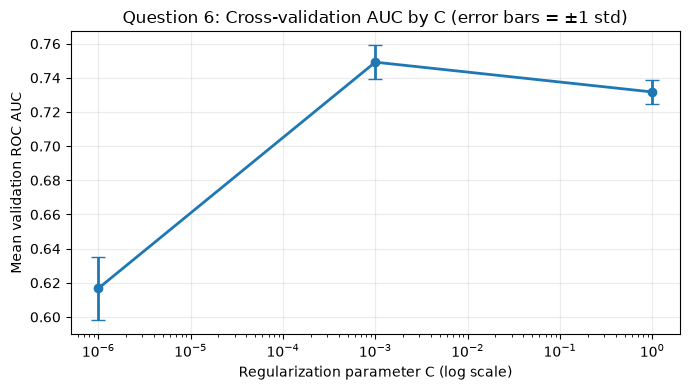

In [12]:
c_values = sorted(cv_results)
mean_aucs = [cv_results[C]['mean_auc'] for C in c_values]
std_aucs = [cv_results[C]['std_auc'] for C in c_values]
plt.figure(figsize=(7, 4))
plt.errorbar(c_values, mean_aucs, yerr=std_aucs, marker='o', capsize=5, linewidth=2)
plt.xscale('log')
plt.xlabel('Regularization parameter C (log scale)')
plt.ylabel('Mean validation ROC AUC')
plt.title('Question 6: Cross-validation AUC by C (error bars = ±1 std)')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Answer summary

| Question | Answer |
|---|---|
| 1 | `lead_score` (AUC ≈ 0.788) |
| 2 | Validation AUC ≈ **0.732** |
| 3 | Precision and recall are closest at threshold **0.63** |
| 4 | F1 is maximal at threshold **0.41** |
| 5 | 5-fold AUC standard deviation ≈ **0.007** |
| 6 | Best mean AUC: **C = 0.001** |